# Train & Evaluate: SuperKart Sales Forecasting

Trains the single-pipeline model (preprocessing + XGBoost) that the local API serves. The same `src/` code runs here and in the Flask service, so there is no training/serving skew. Logic in `src/train.py` and `src/data.py`.

In [1]:
import sys, pathlib
_root = next(p for p in (pathlib.Path.cwd(), pathlib.Path.cwd().parent) if (p/'src').exists())
sys.path.insert(0, str(_root))
import numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from src.data import load_xy
from src.train import build_pipeline, train

In [2]:
X, y = load_xy()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
pipe = build_pipeline().fit(Xtr, ytr)
pred = pipe.predict(Xte)
print(f'R2   : {r2_score(yte, pred):.3f}')
print(f'RMSE : {np.sqrt(mean_squared_error(yte, pred)):.1f}')
print(f'MAE  : {mean_absolute_error(yte, pred):.1f}')
print(f'MAPE : {np.mean(np.abs((yte-pred)/yte))*100:.2f}%')

R2   : 0.928
RMSE : 287.0
MAE  : 120.3
MAPE : 4.41%


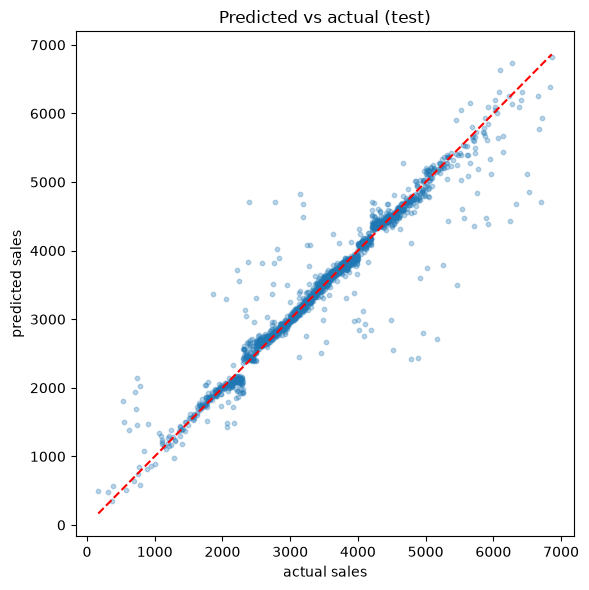

In [3]:
plt.figure(figsize=(6,6))
plt.scatter(yte, pred, alpha=0.3, s=10)
lims=[yte.min(), yte.max()]; plt.plot(lims, lims, 'r--')
plt.xlabel('actual sales'); plt.ylabel('predicted sales'); plt.title('Predicted vs actual (test)')
plt.tight_layout(); plt.savefig(_root/'results'/'pred_vs_actual.png', dpi=120); plt.show()

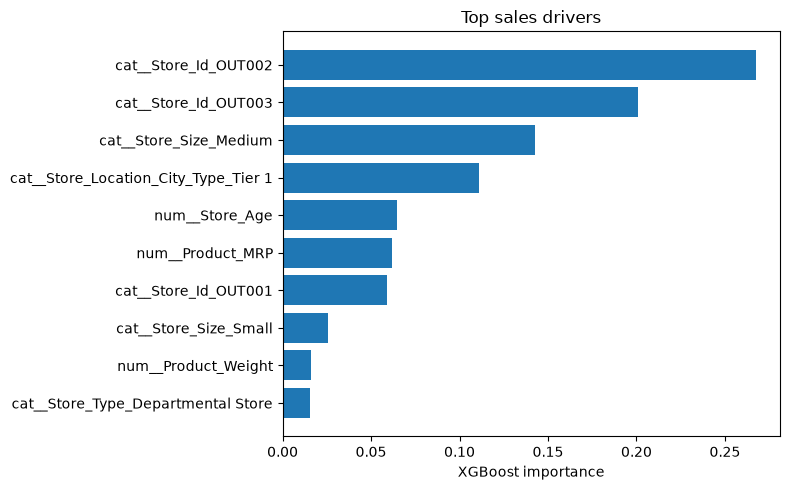

In [4]:
# Feature importance from the fitted XGBoost step
names = pipe.named_steps['prep'].get_feature_names_out()
imp = pipe.named_steps['model'].feature_importances_
order = np.argsort(imp)[::-1][:10][::-1]
plt.figure(figsize=(8,5)); plt.barh([names[i] for i in order], imp[order])
plt.xlabel('XGBoost importance'); plt.title('Top sales drivers'); plt.tight_layout()
plt.savefig(_root/'results'/'feature_importance.png', dpi=120); plt.show()

In [5]:
# Persist the artifact the API loads
_, metrics = train(save=True)
print('saved model; test metrics:', {k: round(v,3) for k,v in metrics.items()})

saved model; test metrics: {'r2': 0.928, 'rmse': 286.958, 'mae': 120.29, 'mape_pct': 4.409}


The saved `models/superkart_pipeline.pkl` is exactly what `api/app.py` loads. Run the API with `uv run python api/app.py`, then the UI with `uv run streamlit run frontend/streamlit_app.py`. See the README.